# Lab 5: our CFD against Ghia and seven-Re coverage

**Aim of Lab 5.** Audit our CFD against the published benchmark, distinguish
reference coverage from numerical qualification, and determine what each neural
model actually predicts. Tables A-C cover CFD, centreline regression and evidence
availability; Table D links these checks to the full-field corner diagnostic.

This standalone CPU lab follows the original Week 1/1.2 and Week 4 CFD lessons.
It widens the **reference and experimental parameter range** to $Re=100,400,1000,3200,5000,7500,10000$.
Ghia's Tables I and II give 17 samples on each centreline, not a full flow field.
The square cavity has width $L$, lid speed $U$, $Re=UL/\nu$, and a discontinuous
moving lid at its upper corners. A smooth-lid or deep cavity is a different problem.

[Benchmark source and anomaly policy](../../references/ghia/README.md) ·
[Experiment, results and limitations](../../results/cavity_ghia_allre/README.md) ·
[Setup](../../START_HERE.md).

Three suspicious **printed** entries remain in the raw tables. We show both the
unfiltered score and a predeclared screened sensitivity score; we never silently
replace them with a plausible number. A train/test split by individual points
would leak the same Reynolds number into both sets.

For $N$ retained samples, report
$$E_u=\frac{\sqrt{\sum_i(\hat u_i-u_i)^2}}{\sqrt{\sum_i u_i^2}},\qquad
e_{\mathrm{RMS},u}/U=\sqrt{\frac1N\sum_i[(\hat u_i-u_i)/U]^2}.$$
Use the analogous definitions for $v$. The norm denominator is shared over the
profile, so a reference zero crossing causes no pointwise division by zero.
The code stores velocities already divided by $U$.


**Start with our computed solutions below.** This notebook now opens the native
FlowMLLab CFD archives, recomputes their errors, and plots CFD curves against
Ghia markers by default. It does not fit a curve through Ghia and call it CFD.
Retained CFD now covers all seven Ghia Reynolds numbers. Table A revisits the
earlier Re=100/400/1000 grids; Table C lists the current field archives, including
the 512-cell cases. [Lab 7](W4_Lab7_High_Re_CFD_Ghia.ipynb) supplies their mesh/time
checks. Availability alone does not establish grid-independent accuracy.

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab5_All_Re_Ghia_Validation.ipynb)

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

### 1. Our CFD solutions, mesh changes and Ghia validation

Re=100 uses the existing staggered-grid SIMPLE runs on 32/64 cells. Re=400 and
1000 use the existing independent finite-difference streamfunction-vorticity
runs on 32/64/128 cells. Every archive is checked against its recorded SHA256.
For SIMPLE, centreline velocities come from the native MAC faces with the
prescribed wall values. For FD, we interpolate the actual two-dimensional field.

Table A recomputes the profile errors from these fields. Both the original
printed-data score and the predeclared sensitivity score are shown. Native
momentum and vorticity defects belong to different equations; their magnitudes
cannot rank the methods. A passed iteration gate does not establish mesh or
physical-time convergence.

In [2]:
if not (ROOT/'flowmllab/cavity_validation.py').is_file():
    raise RuntimeError('Use FlowMLLab v1.12.1 or later. Save your work, then update the checkout; do not overwrite your edited notebook.')
from flowmllab import cavity_validation as validation
cfd = validation.load_evidence(ROOT)
cfd_scores = pd.DataFrame(validation.score_rows(cfd))
print('Table A: measured errors of our retained CFD against Ghia')
columns = ['Re', 'method', 'cells', 'recorded_converged',
           'u_published_relative_l2', 'v_published_relative_l2',
           'v_screened_relative_l2', 'u_screened_rmse_U', 'v_screened_rmse_U',
           'recorded_steady_defect', 'native_equation']
display(cfd_scores[columns])
print('The relative-L2 columns are fractions (multiply by 100 for percent).')
print('Source archives and hashes:')
display(cfd_scores[['Re','cells','source','sha256']])

Table A: measured errors of our retained CFD against Ghia


,Re,method,cells,recorded_converged,u_published_relative_l2,v_published_relative_l2,v_screened_relative_l2,u_screened_rmse_U,v_screened_rmse_U,recorded_steady_defect,native_equation
0,100,simple,32,True,0.002847,0.026867,0.026867,0.001301,0.003584,8.538181e-08,momentum_residual_linf
1,100,simple,64,True,0.003954,0.032607,0.032607,0.001807,0.004350,9.283927e-08,momentum_residual_linf
2,400,streamfunction-vorticity,32,True,0.118876,0.267283,0.274048,0.050802,0.065468,1.398837e-08,steady_vorticity_linf
3,400,streamfunction-vorticity,64,True,0.029299,0.136233,0.058566,0.012521,0.013991,1.540279e-08,steady_vorticity_linf
4,400,streamfunction-vorticity,128,True,0.006019,0.146628,0.008972,0.002572,0.002143,1.496847e-08,steady_vorticity_linf
5,1000,streamfunction-vorticity,32,True,0.346874,0.601440,0.601440,0.141856,0.187336,1.927267e-08,steady_vorticity_linf
6,1000,streamfunction-vorticity,64,True,0.092799,0.130412,0.130412,0.037951,0.040621,2.593126e-08,steady_vorticity_linf
7,1000,streamfunction-vorticity,128,True,0.019881,0.017042,0.017042,0.008130,0.005308,2.892619e-08,steady_vorticity_linf


The relative-L2 columns are fractions (multiply by 100 for percent).
Source archives and hashes:


,Re,cells,source,sha256
0,100,32,results/week01_2_pressure_velocity/simple-re10...,643f7f3758403a5b3f0da5448edcc65946aa04509a29e5...
1,100,64,results/week01_2_pressure_velocity/simple-re10...,4ce6777c09aea15ef9235246dad10ca95f0c33eb4ebcf5...
2,400,32,results/week01_2_formulations/streamfunction-v...,bee636d538bba0384b9798e70d23b5f2bbfd77e5ca495d...
3,400,64,results/week01_2_formulations/streamfunction-v...,452c840729aecbb74f9486c72f584ae07c0c374410de09...
4,400,128,results/week01_2_formulations/streamfunction-v...,0189db217fbca28715aba673fe3285180094230c028f92...
5,1000,32,results/week01_2_formulations/streamfunction-v...,71aa482837048e8c2ecb32ab461c945f291f98f202d1b6...
6,1000,64,results/week01_2_formulations/streamfunction-v...,3002469df010b5ce884aae92b48042c493708eb8f9eddf...
7,1000,128,results/week01_2_formulations/streamfunction-v...,8b72232e01afa6429ba9f72199b901fe7f90d266ed169c...


Actual FlowMLLab CFD streamlines: SIMPLE at Re=100; FD at Re=400 and 1000.


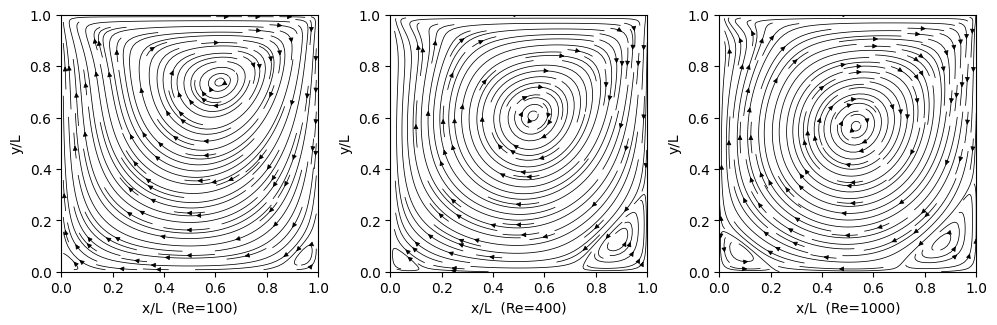

Re=100: our CFD on retained grids versus Ghia, then signed sample errors


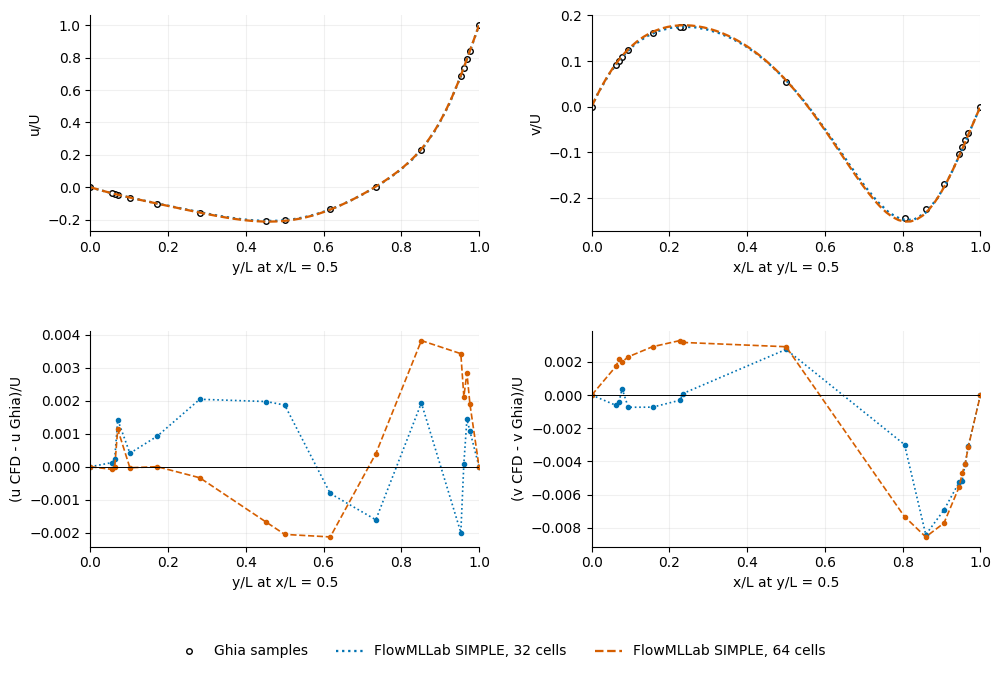

Re=400: our CFD on retained grids versus Ghia, then signed sample errors


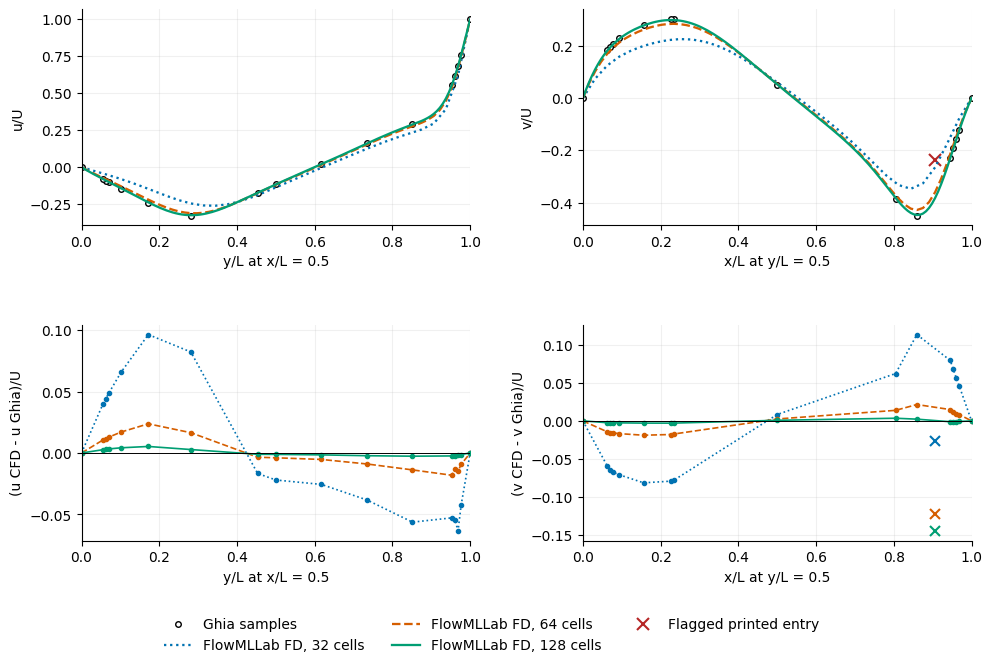

Re=1000: our CFD on retained grids versus Ghia, then signed sample errors


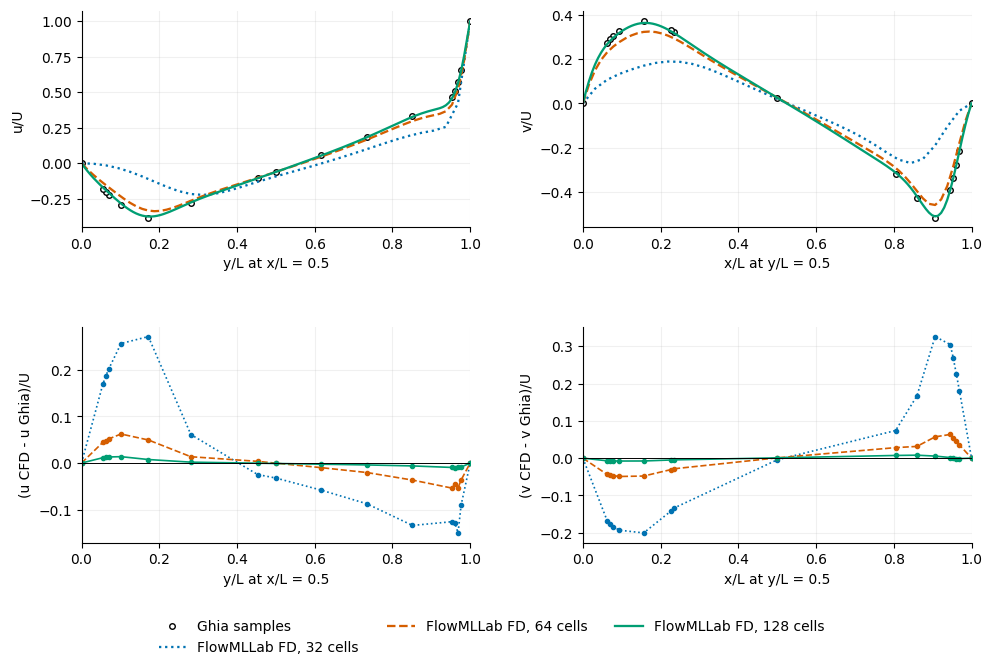

In [3]:
print('Actual FlowMLLab CFD streamlines: SIMPLE at Re=100; FD at Re=400 and 1000.')
validation.plot_streamlines(cfd)
plt.show()
for re in (100, 400, 1000):
    print(f'Re={re}: our CFD on retained grids versus Ghia, then signed sample errors')
    validation.plot_profiles(cfd, re)
    plt.show()

Read the changes in the velocity profiles before reading the scalar score.
At Re=400, the marked printed v value near x/L=0.9063 strongly affects the
all-point norm. Its signed discrepancy remains visible; screening does not
replace the published value. At Re=100, these two SIMPLE grids do not give a
monotone Ghia-error reduction. Report that outcome rather than claiming a
successful convergence study. The original source and histories remain in
[Re=100 evidence](../../results/week01_2_pressure_velocity/README.md) and
[Re=400/1000 evidence](../../results/week01_2_formulations/README.md).

### 2. What we have for neural learning on the Ghia cases

There are three distinct retained supervised experiments:

* **Low-Re full fields:** the introductory POD-DeepONet learns 65 by 65 velocity and pressure
  fields from our CFD over Re=100--400. Its blind cases are Re=175, 275 and 375.
  Ghia checks at Re=100 and 400 are not unseen-Re tests of that model.
  [Full-field results and protocol](../../results/pod_deeponet/README.md).
* **All-seven-Re profile study:** a small MLP learns u(y) and v(x) directly from
  Ghia centreline samples. Training uses Re=100,1000,5000,10000; validation uses
  400; complete test cases are 3200 and 7500. Adam, L-BFGS, their sequence, network
  depth and wall-data weights are compared across three seeds. These are profile
  fits, not independent CFD solutions or label-free PINNs.
* **High-Re full fields:** a separate POD-DeepONet learns our matched CFD velocity
  fields over Re=100--10000, with Re=3200 and 7500 withheld in full and Re=400/6500
  used for selection. [Lab 8](W4_Lab8_High_Re_Field_DeepONet.ipynb) compares frozen
  predictions with interpolation. Its small surrogate errors are relative to the
  retained 512-cell discretization, whose mesh sensitivity is reported separately.

The figures below show the frozen baseline, selected network and interpolation
against the held-out Ghia samples. Their lower panels show signed discrepancies
at measured reference locations. Curves are three-seed means; Table B averages
individual-seed errors. The original printed-data sensitivities remain in the
CSV. [Lab 6](W4_Lab6_Ghia_Profile_Optimizer_Depth.ipynb) gives the complete training
protocol, all seven plots, source models and architecture/optimizer exercises.

Table B: mean u/v RMSE divided by U, averaged over individual seeds


Re,3200,7500
model,,
adam_2,0.033949,0.038002
hybrid_5_wall,0.019739,0.005627
linear_logRe,0.016294,0.005176


Re=3200: held-out Ghia-profile prediction; these curves are not a CFD solve


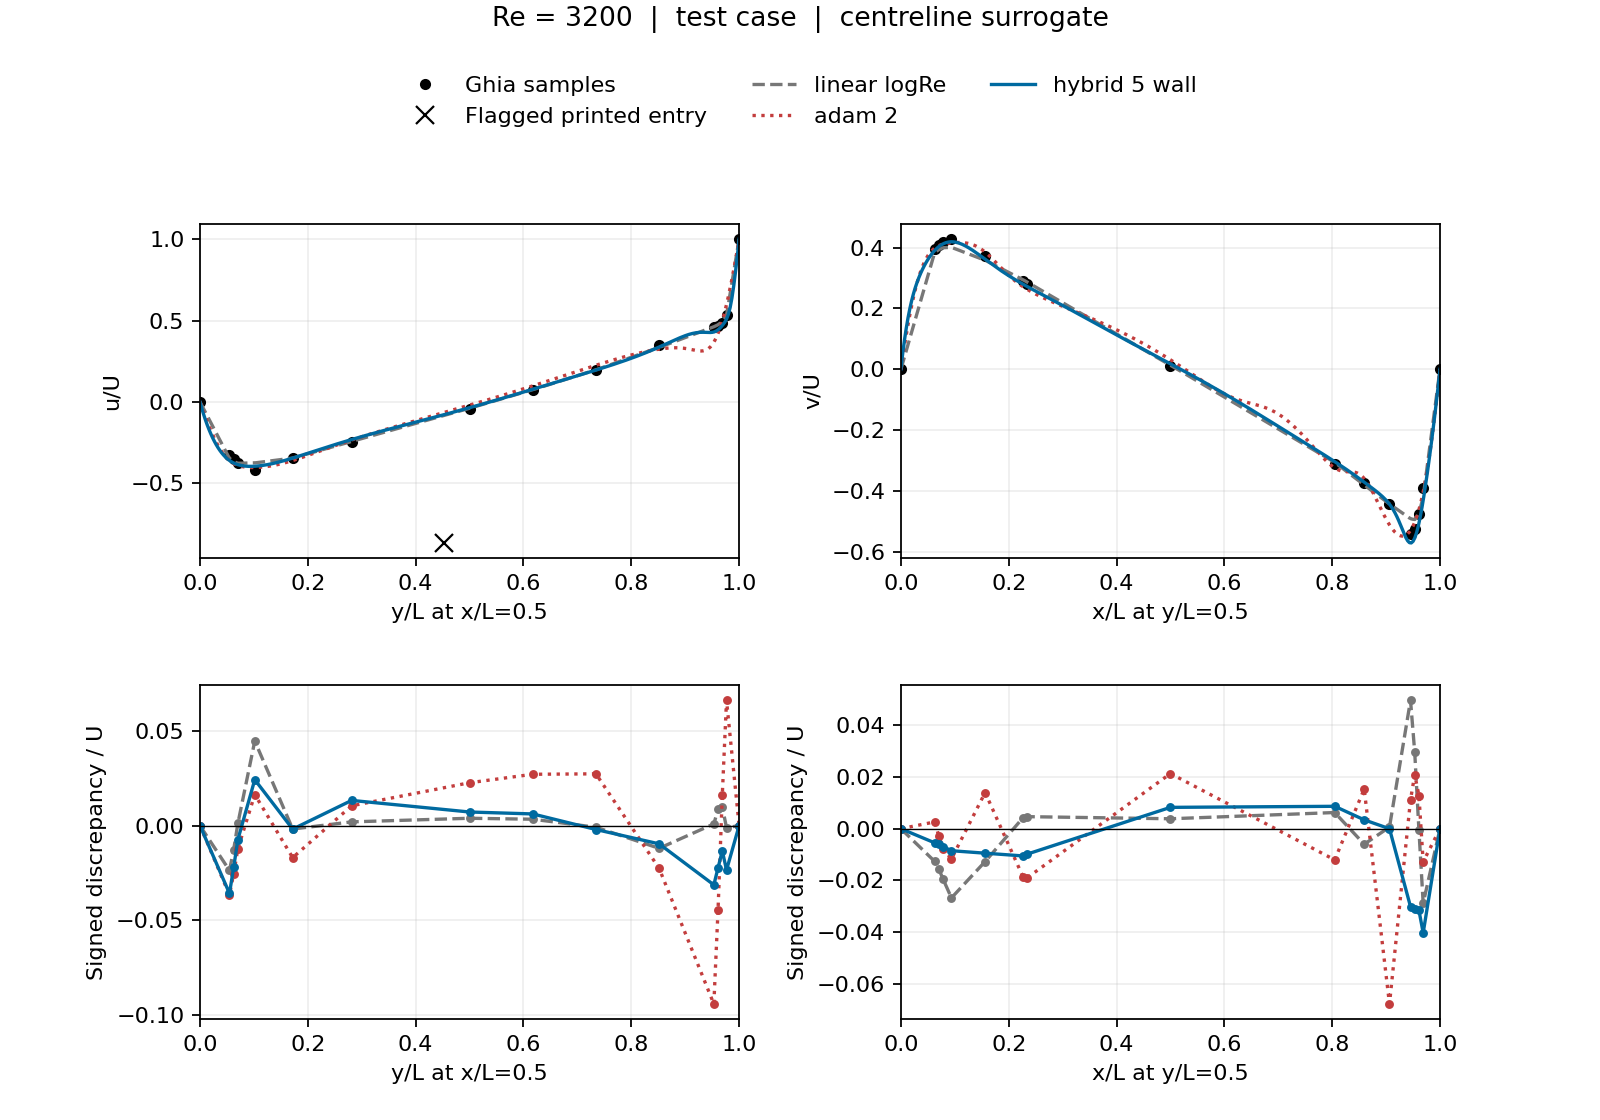

Re=7500: held-out Ghia-profile prediction; these curves are not a CFD solve


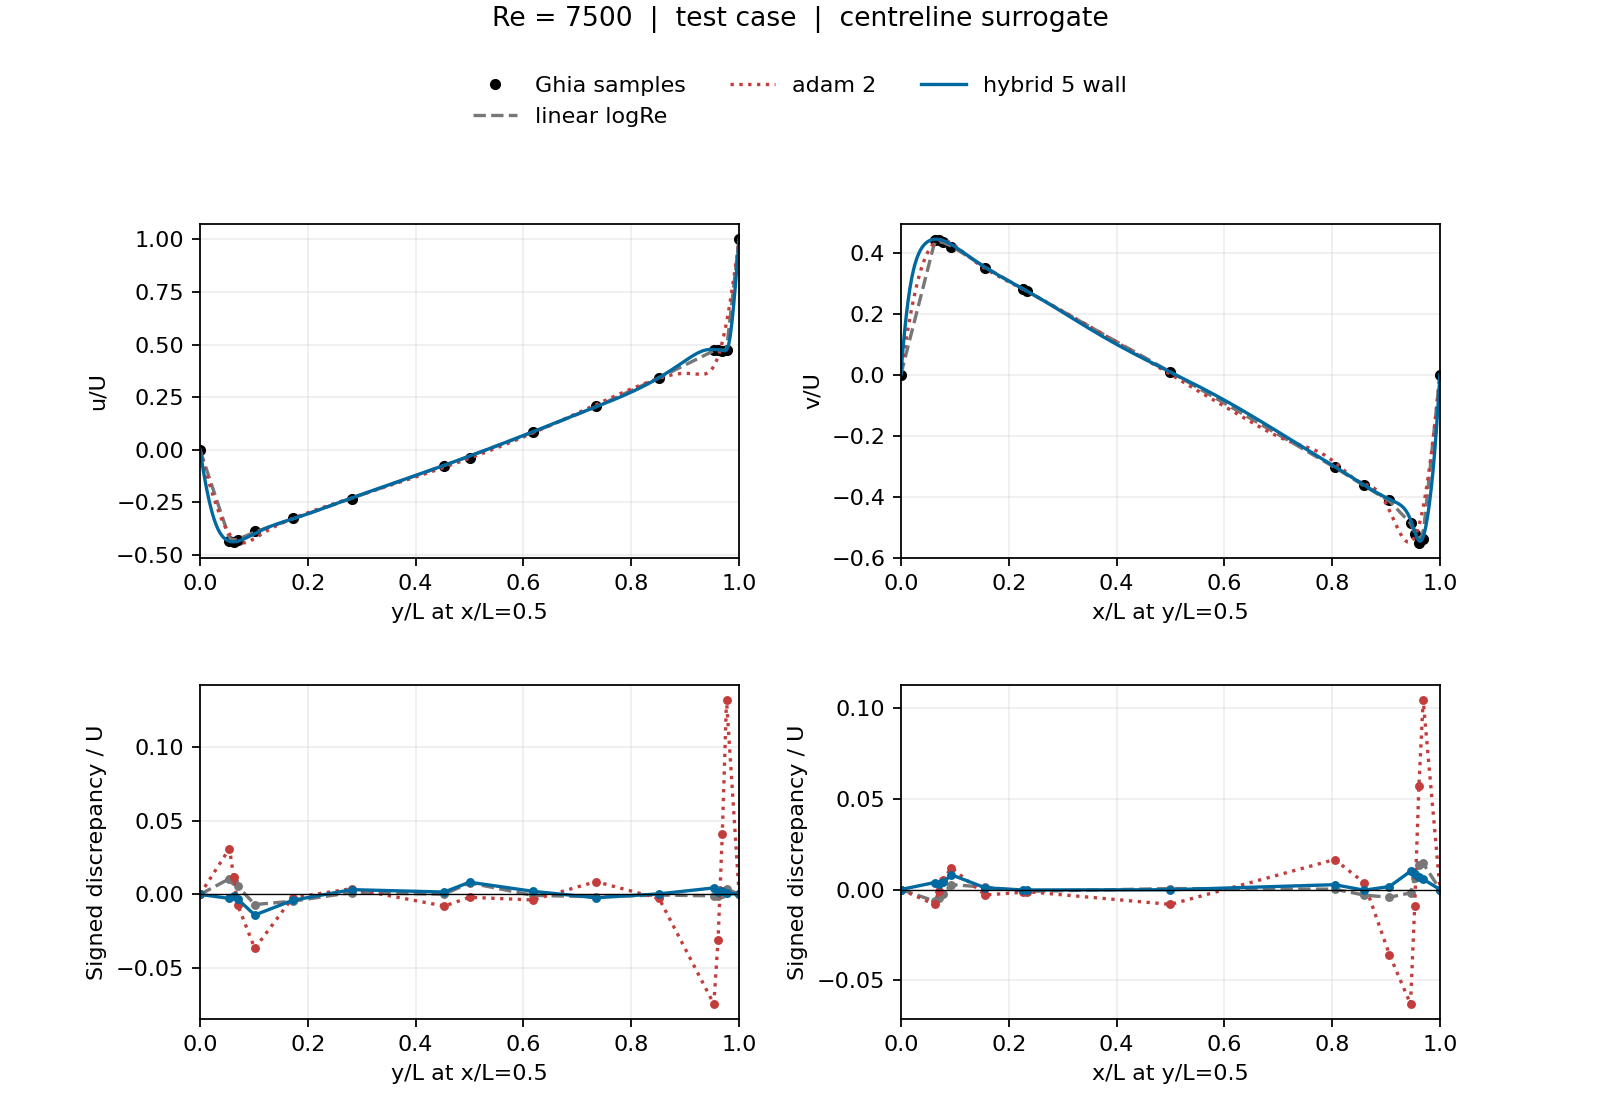

The selected neural model improves over Adam, but log-Re interpolation wins both tests.


In [4]:
course.verify_frozen_models(ROOT)
neural_folder = ROOT/'results/cavity_ghia_allre'
measured = pd.read_csv(neural_folder/'scores.csv')
per_seed = measured.groupby(['model','Re','role','seed'])['rmse_U'].mean().reset_index()
test = per_seed[(per_seed.role == 'test') & per_seed.model.isin(
    ['adam_2','hybrid_5_wall','linear_logRe'])]
print('Table B: mean u/v RMSE divided by U, averaged over individual seeds')
display(test.groupby(['model','Re']).rmse_U.mean().unstack('Re'))
for re in (3200, 7500):
    print(f'Re={re}: held-out Ghia-profile prediction; these curves are not a CFD solve')
    display(Image(filename=str(neural_folder/f're{re}_profiles.png'), width=800))
print('The selected neural model improves over Adam, but log-Re interpolation wins both tests.')

### 3. Current coverage and numerical qualification

Table C checks the actual files in this checkout. Retained 512-cell CFD fields
are present for all seven reference cases; this table reports availability,
not a new solve or a claim of mesh independence. A Ghia profile table and a
full-field CFD archive remain different forms of evidence.

Use [Lab 7](W4_Lab7_High_Re_CFD_Ghia.ipynb) and its
[mesh/time evidence](../../results/cavity_highre_ghia/README.md) to inspect grid,
time step, convection, residual history, wall treatment and both velocity
profiles. Compare the retained three-grid and time-step checks, stationarity,
mass balance and vortex locations before admitting a field as a learning label.
Pressure needs separate qualification: Ghia's velocity samples do not validate it.
If a file is absent in your checkout, Table C reports that local absence; recover
the matching published evidence before using it.

In [5]:
print('Table C: reference and retained CFD coverage')
display(pd.DataFrame(course.coverage(ROOT)))
# Reference-only figures are optional: the default plots above contain OUR solutions.
SHOW_REFERENCE_ONLY = False
if SHOW_REFERENCE_ONLY:
    for re in ghia.REYNOLDS:
        print(f'Re={re}: published samples only')
        course.plot_reference(re)
        plt.show()

Table C: reference and retained CFD coverage


,Re,reference_samples,flagged_samples,profile_study_role,retained_field,scope
0,100,34,0,train,results/cavity_highre_ghia/n512/re100.npz,retained evidence; inspect its own mesh/steady...
1,400,34,1,validation,results/cavity_highre_ghia/n512/re400.npz,retained evidence; inspect its own mesh/steady...
2,1000,34,0,train,results/cavity_highre_ghia/n512/re1000.npz,retained evidence; inspect its own mesh/steady...
3,3200,34,1,test,results/cavity_highre_ghia/n512/re3200.npz,retained evidence; inspect its own mesh/steady...
4,5000,34,0,train,results/cavity_highre_ghia/n512/re5000.npz,retained evidence; inspect its own mesh/steady...
5,7500,34,0,test,results/cavity_highre_ghia/n512/re7500.npz,retained evidence; inspect its own mesh/steady...
6,10000,34,1,train,results/cavity_highre_ghia/n512/re10000.npz,retained evidence; inspect its own mesh/steady...


In [6]:
# Optional new CFD: choose one case and audit it before treating it as a field label.
RUN_NEW_CFD = False
RE_TO_SOLVE = 3200
CELLS = 128
if RUN_NEW_CFD:
    from flowmllab.streamfunction_experiments import run_streamfunction
    field = run_streamfunction(reynolds=RE_TO_SOLVE, cells=CELLS,
                              dt=0.0005, max_steps=400000, progress=False)
    display({k:field[k] for k in ['status','steps','steady_vorticity_linf',
                                'continuity_linf','ghia_u_relative_l2','ghia_v_relative_l2']})
    display(course.compare_field(RE_TO_SOLVE,field['x'],field['y'],field['u'],field['v']))
else:
    print('Retained CFD and neural results above were loaded and evaluated; no new CFD run requested.')

Retained CFD and neural results above were loaded and evaluated; no new CFD run requested.


### 4. Does the field model resolve the upper-left vortex?

**Aim.** Separate a weak flow structure, a plotting omission and a genuine
prediction error. The profile networks in Table B predict only the two
centreline curves: they do **not** define a two-dimensional velocity field and
cannot predict a vortex location. This section therefore opens the **separate
frozen full-field POD-DeepONet from Lab 8**, at its whole-Re test cases 3200 and
7500. No model is retrained or selected here.

We examine the same native $513\times513$ fields in
$0\leq x/L\leq0.25$, $0.65\leq y/L\leq1$. Under
$u=\partial\psi/\partial y$, $v=-\partial\psi/\partial x$, a positive interior
streamfunction island counter-rotates relative to the main negative island.
Its native-node maximum gives a discrete centre and its maximum value gives
a circulation-strength proxy. This is not an independently validated vortex
position; a one-cell displacement is $L/512$. A small whole-field relative
error can conceal a large local error, so Table D reports both norms, the
signed peak-strength discrepancy and the centre displacement.

The first panel fills the CFD streamfunction and overlays all three methods at
**identical physical contour levels**. A symmetric-log scale exposes weak
positive islands while retaining all CFD extrema; it is linear near zero.
The two vector-error maps share a **linear** scale from zero to the largest
error across both methods in this window. Neither is clipped or independently
rescaled to look better. The fixed off-centre cuts at $x/L=0.06$ and $y/L=0.90$
show velocities and signed discrepancies; they are not Ghia centreline samples.

This is a **post-hoc physical diagnostic of already frozen tests**, not a new
blind test or a basis for further tuning on these targets. The retained CFD
mesh sensitivity and steady-branch limitations in Lab 7 remain in force.


Table D: whole-field and upper-left-window errors, fractions rather than percent


,Re,method,field_relative_l2,corner_relative_l2,corner_vector_rms_U,corner_vector_max_U,resolved_positive_island,x_peak_L,y_peak_L,psi_peak_UL,peak_shift_L,peak_strength_signed_relative_error
0,3200,CFD,0.000000,0.000000,0.000000,0.000000,True,0.054688,0.898438,0.000709,0.000000,0.000000
1,3200,POD-DeepONet,0.000951,0.000957,0.000269,0.001059,True,0.054688,0.898438,0.000704,0.000000,-0.007954
2,3200,Linear in log Re,0.005394,0.003969,0.001115,0.003378,True,0.052734,0.900391,0.000665,0.002762,-0.063074
3,7500,CFD,0.000000,0.000000,0.000000,0.000000,True,0.066406,0.914062,0.002104,0.000000,0.000000
4,7500,POD-DeepONet,0.000844,0.000768,0.000220,0.000848,True,0.068359,0.914062,0.002100,0.001953,-0.001661
5,7500,Linear in log Re,0.003139,0.003269,0.000935,0.003533,True,0.068359,0.912109,0.002101,0.002762,-0.001008


Re=3200: native 513 x 513 fields; frozen held-out prediction; same log-Re interpolation labels


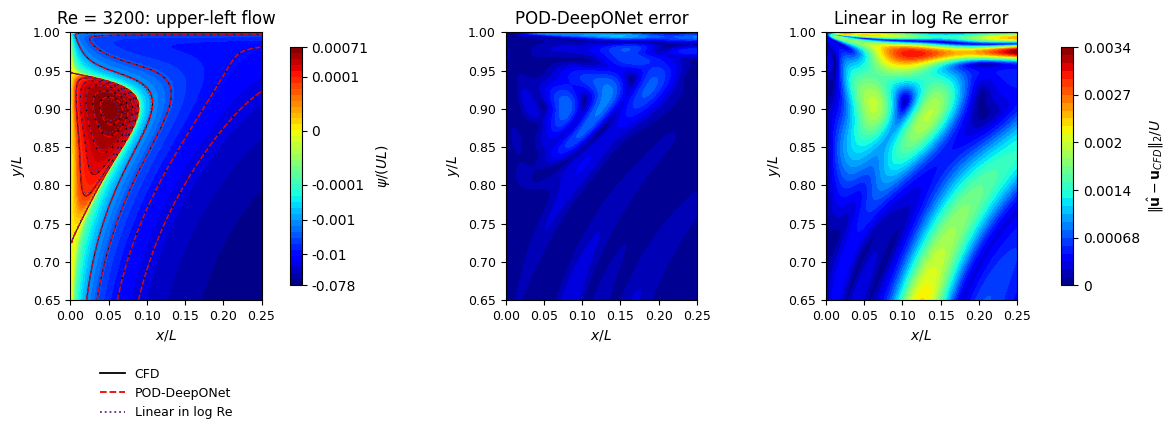

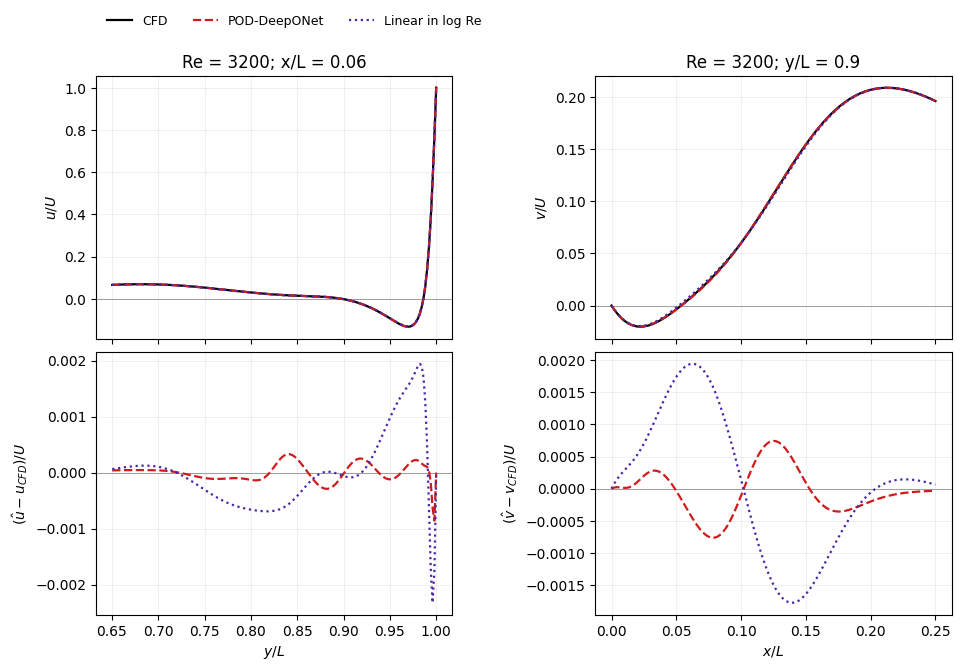

Re=7500: native 513 x 513 fields; frozen held-out prediction; same log-Re interpolation labels


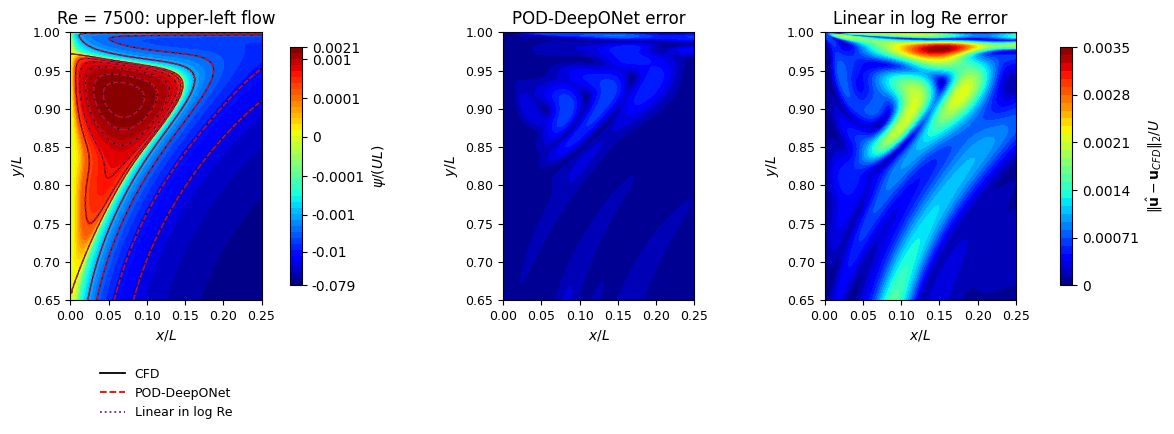

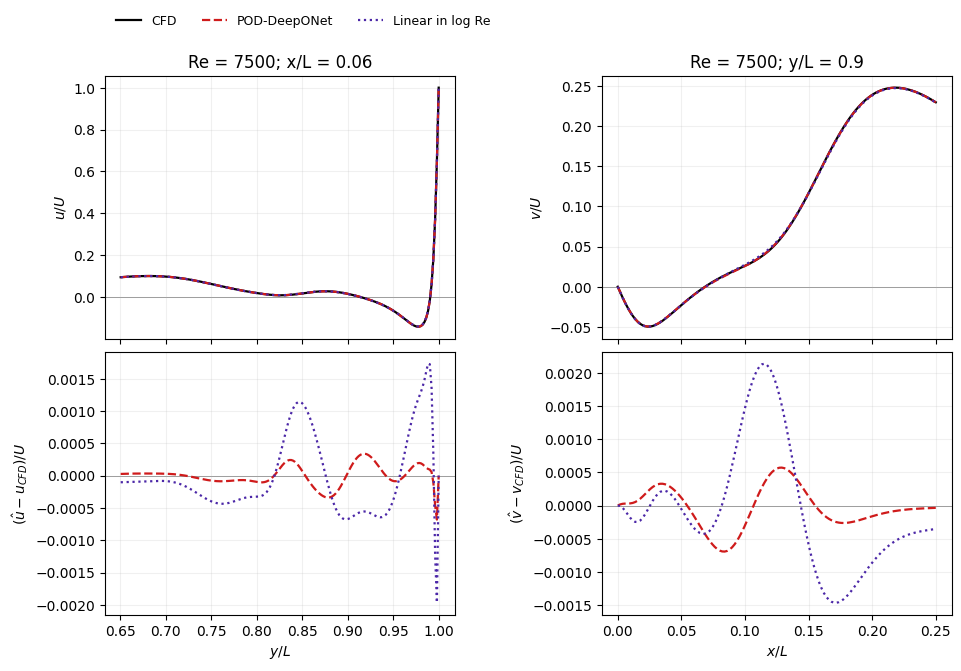

In [7]:
from flowmllab import cavity_corner_audit as corner
corner_cases, corner_provenance = corner.load_frozen_cases(ROOT)
corner_scores = pd.DataFrame(corner.diagnostic_rows(corner_cases))
print('Table D: whole-field and upper-left-window errors, fractions rather than percent')
display(corner_scores[['Re','method','field_relative_l2','corner_relative_l2',
    'corner_vector_rms_U','corner_vector_max_U','resolved_positive_island',
    'x_peak_L','y_peak_L','psi_peak_UL','peak_shift_L',
    'peak_strength_signed_relative_error']])
for re, methods in corner_cases.items():
    print(f'Re={re}: native 513 x 513 fields; frozen held-out prediction; same log-Re interpolation labels')
    corner.plot_corner(methods, re)
    plt.show()
    corner.plot_corner_profiles(methods, re)
    plt.show()


#### Read the corner comparison and design the next experiment

1. For each test Reynolds number, compare the neural model with interpolation
   using both the whole-field and corner norms in Table D. Determine which
   method improves or deteriorates on the local velocity cuts.
2. Locate each positive streamfunction maximum, express its displacement in
   units of the native grid spacing, and report the signed relative change in
   peak strength. If no resolved positive island exists, report that rather
   than selecting a wall point and calling it a vortex centre.
3. Explain why a centreline-only MLP cannot answer this question and why a
   default streamline seeding pattern can miss a small island. Change contour
   levels or zoom limits to inspect the same unchanged field; do not train on
   test errors or change the stored predictions.
4. A proposed network improvement needs an independent development target:
   choose sampling, capacity and loss weights using training/validation cases,
   freeze the procedure, then evaluate on a new reserved test. Retain the
   current frozen result as the comparison. Stronger corner weights can improve
   a local region while worsening global errors or other corners.
5. Read the Lab 7 mesh-change results before claiming physical accuracy. These
   comparisons measure fidelity to a particular numerical steady solution,
   not three-dimensional stability or a mesh-independent exact solution.

[Full-field model and frozen protocol](../../results/cavity_field_deeponet/README.md)
 · [Machine-readable corner results](../../results/week04_corner_audit/README.md)


### Specific student tasks

1. **Table A and the three CFD figures:** report the u/v errors for every retained
   grid. Locate the largest signed discrepancy and explain the nonmonotone
   Re=100 result. For Re=400, explain the difference between raw and screened v
   norms using the marked sample. Do not choose a mask from your observed error.
2. **Spatial evidence:** identify the primary vortex in each actual CFD field.
   Describe which corner structures the present grids resolve. Ghia's two
   centreline tables alone cannot validate a complete vortex map or pressure.
3. **Table B and the two test figures:** compare Adam, the selected network and
   interpolation separately at Re=3200 and 7500. State where the neural model
   gains and loses, and distinguish seed-mean error from error of the mean curve.
4. **Information and test sets:** list the labels, selection cases and blind
   Re values for the low-Re field model, the centreline MLP and the high-Re field
   model in Lab 8. Explain why profile fitting and a label-free PINN solve are
   different claims, even when evaluated at the same Reynolds number.
5. **Table C and Lab 7:** select one high-Re case and inspect its three-grid and
   time-step evidence. Write an admission decision that separates file presence,
   iterative convergence, mesh sensitivity and benchmark agreement. State a
   further check if the retained evidence is insufficient; do not call a missing
   local download a missing scientific experiment.
6. **Algorithm comparison:** use the original Week 1.2 matched SIMPLE/PISO/PIMPLE
   runs to compare pressure solves and elapsed time at equal achieved accuracy.
   SIMPLE iterations are not physical time. Do not infer an algorithm ranking
   by comparing the different Re/method combinations in this notebook.